# Stage 3b – A Tabular Foundation Model (TabICL v2)

Adds a fifth model: **TabICL v2**, a transformer pre-trained on synthetic tables that predicts new customers from the training data without training or tuning (Qu et al., 2026). Deep learning trained from scratch is not used because tree ensembles are usually stronger on small tables (Grinsztajn et al., 2022).

**Design:** released settings (no tuning, seed 42); same 25 inputs, same 5 folds, same calibration options (chosen by CV Brier), same metrics and same single test-set evaluation as Stage 3; no instance weights.

## Step 1 – Setup, data and the Stage 3 folds

In [1]:
# Cell 1 - Setup
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import brier_score_loss

ROOT = Path.cwd()
if ROOT.name in ("src", "notebooks"):
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

import config as C
from src import features as F
from src import modelling as M

assert C.TABICL_CHECKPOINT.exists(), f"TabICL checkpoint not found: {C.TABICL_CHECKPOINT}"

train = pd.read_csv(C.PROCESSED_DIR / "train_segmented.csv")
test = pd.read_csv(C.PROCESSED_DIR / "test_segmented.csv")
SEGMENTS = ["Low-value", "New high-value", "Established high-value"]
X_train, y_train = F.get_X_y(train.drop(columns=["segment", "segment_k4"]))
X_test, y_test = F.get_X_y(test.drop(columns=["segment", "segment_k4"]))
y_train, y_test = y_train.to_numpy(), y_test.to_numpy()
clv_train, clv_test = M.customer_value(train), M.customer_value(test)
D = clv_train.mean() * C.INCENTIVE_RATIO

# The same five folds as Stage 3 (same splitter and seed)
fold_id = np.zeros(len(y_train), dtype=int)
for k, (_, va) in enumerate(StratifiedKFold(C.CV_FOLDS, shuffle=True,
                                            random_state=C.RANDOM_STATE).split(X_train, y_train)):
    fold_id[va] = k

# Stage 3 predictions (for comparison) and the calibration selected in Stage 3
oof_s3 = pd.read_csv(C.PROCESSED_DIR / "stage3_oof_predictions.csv")
test_s3 = pd.read_csv(C.PROCESSED_DIR / "stage3_test_predictions.csv")
assert (oof_s3[C.ID_COL] == train[C.ID_COL]).all() and (test_s3[C.ID_COL] == test[C.ID_COL]).all()
chosen_s3 = (pd.read_csv(C.TABLES_DIR / "15_cv_selected_calibration.csv")
             .set_index(["model", "condition"])["calibration"])

MODEL_COLOURS = {"Logistic regression": "#2a78d6", "Random forest": "#1baf7a",
                 "LightGBM": "#eda100", "SVM": "#4a3aa7", "TabICL v2": "#d6402a"}
CAL_STYLES = {"raw": ":", "Platt": "--", "isotonic": "-"}
GREY = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#2b2b2b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(C.FIGURES_DIR / f"{name}.png")
    print("Saved figure:", name)

def save_table(df, name):
    df.to_csv(C.TABLES_DIR / f"{name}.csv")
    print("Saved table:", name)

import torch
from importlib.metadata import version
print(f"Train {len(train):,} | test {len(test):,} | incentive d = {D:.2f} | "
      f"torch {torch.__version__} | tabicl {version('tabicl')} | device: cpu")

Train 5,625 | test 1,407 | incentive d = 39.00 | torch 2.2.2 | tabicl 2.2.0 | device: cpu


## Step 2 – TabICL predictions (cross-validation and test set)
For each fold, the training part is the context and the held-out part is predicted. Slow on a CPU; predictions are cached in `outputs/models/stage3b_tabicl_predictions.joblib` (delete to recompute).

In [2]:
# Cell 2 - Out-of-fold and test predictions
PRED_FILE = C.MODELS_DIR / "stage3b_tabicl_predictions.joblib"
if PRED_FILE.exists():
    tab = joblib.load(PRED_FILE)
    print(f"Loaded saved TabICL predictions (computed in {tab['seconds']:.0f} s)")
else:
    t0 = time.time()
    oof_score, oof_raw, cv_auc = M.cross_validate("TabICL v2", {}, "none", X_train, y_train,
                                                  clv_train, D, fold_id, F.make_encoder)
    enc, model = M.fit_one("TabICL v2", {}, "none", X_train, y_train, clv_train, D, F.make_encoder)
    test_score, test_raw = M.model_outputs(model, enc.transform(X_test))
    tab = {"oof_score": oof_score, "oof_raw": oof_raw, "cv_auc": cv_auc,
           "test_score": test_score, "test_raw": test_raw, "seconds": time.time() - t0}
    joblib.dump(tab, PRED_FILE)
    print(f"TabICL done in {tab['seconds']:.0f} s")
print(f"Mean fold AUC (cross-validation): {tab['cv_auc']:.4f}")

TabICL done in 588 s
Mean fold AUC (cross-validation): 0.8528


## Step 3 – Cross-fitted calibration and cross-validation results
Same as Stage 3; compared with the Stage 3 models trained without weights.

In [3]:
# Cell 3 - Calibration options for TabICL (CV)
tab_oof = {"raw": tab["oof_raw"],
           "Platt": M.cross_fit_calibration("Platt", tab["oof_score"], y_train, fold_id),
           "isotonic": M.cross_fit_calibration("isotonic", tab["oof_score"], y_train, fold_id)}
COLS = ["AUC", "PR-AUC", "EMP per customer", "Brier", "Log loss", "ECE", "Cal. slope",
        "Cal. intercept", "Mean predicted", "Profit per customer", "Targeted share", "MCC"]
cv_tab = pd.DataFrame({cal: M.evaluate(y_train, p, clv_train, D) for cal, p in tab_oof.items()}).T
cv_tab.index.name = "calibration"
tab_cal = cv_tab["Brier"].idxmin()
print("Selected calibration for TabICL (lowest CV Brier):", tab_cal)
save_table(cv_tab[COLS].round(4), "20_tabicl_cv_calibration")
cv_tab[COLS].round(3)

Selected calibration for TabICL (lowest CV Brier): Platt
Saved table: 20_tabicl_cv_calibration


,AUC,PR-AUC,EMP per customer,Brier,Log loss,ECE,Cal. slope,Cal. intercept,Mean predicted,Profit per customer,Targeted share,MCC
calibration,,,,,,,,,,,,
raw,0.852,0.672,51.402,0.133,0.409,0.015,0.898,0.054,0.259,52.006,0.485,0.452
Platt,0.852,0.671,51.412,0.132,0.408,0.008,0.998,0.000,0.266,51.698,0.510,0.433
isotonic,0.849,0.663,51.341,0.133,0.411,0.006,0.956,-0.002,0.266,51.752,0.507,0.436


In [4]:
# Cell 4 - Five models, no weights, selected calibration (cross-validation selection scores)
S3_MODELS = ["Logistic regression", "Random forest", "LightGBM", "SVM"]
def s3_pred(frame, model):
    return frame[f"{model}|none|{chosen_s3[(model, 'none')]}"].to_numpy()

rows = {f"{m} ({chosen_s3[(m, 'none')]})": M.evaluate(y_train, s3_pred(oof_s3, m), clv_train, D)
        for m in S3_MODELS}
rows[f"TabICL v2 ({tab_cal})"] = M.evaluate(y_train, tab_oof[tab_cal], clv_train, D)
cv_five = pd.DataFrame(rows).T
cv_five.index.name = "model (calibration)"
save_table(cv_five[COLS].round(4), "21_cv_five_models")
cv_five[COLS].round(3)

Saved table: 21_cv_five_models


,AUC,PR-AUC,EMP per customer,Brier,Log loss,ECE,Cal. slope,Cal. intercept,Mean predicted,Profit per customer,Targeted share,MCC
model (calibration),,,,,,,,,,,,
Logistic regression (raw),0.845,0.655,50.769,0.136,0.418,0.015,0.973,-0.000,0.266,51.349,0.510,0.434
Random forest (Platt),0.848,0.660,51.100,0.134,0.413,0.007,0.998,-0.001,0.266,51.862,0.514,0.432
LightGBM (raw),0.849,0.661,51.508,0.134,0.413,0.012,1.049,-0.000,0.266,51.735,0.510,0.437
SVM (isotonic),0.837,0.641,50.732,0.137,0.424,0.011,0.950,-0.001,0.266,51.609,0.497,0.440
TabICL v2 (Platt),0.852,0.671,51.412,0.132,0.408,0.008,0.998,0.000,0.266,51.698,0.510,0.433


## Step 4 – Reliability diagram (cross-validation)

Saved figure: 13_reliability_tabicl_cv


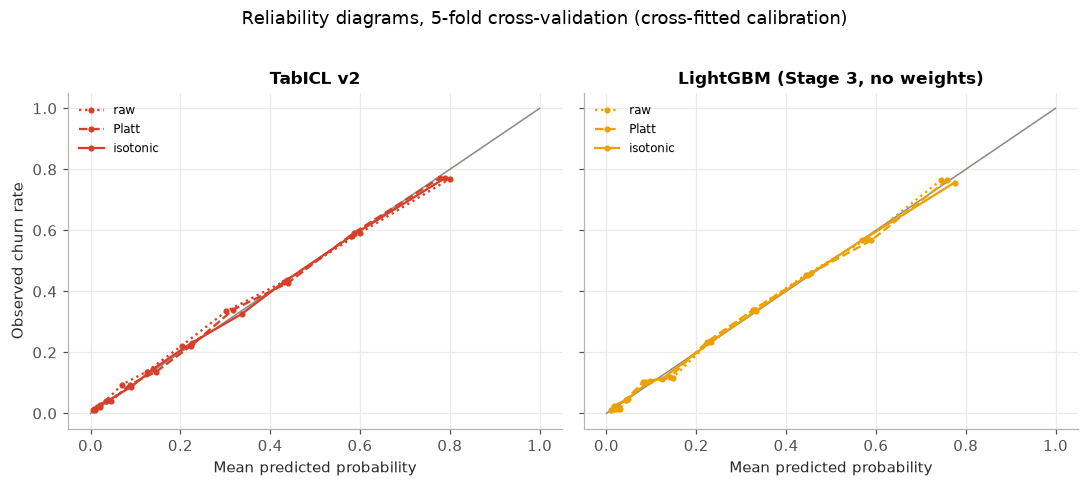

In [5]:
# Cell 5 - Reliability diagrams
def reliability_points(y, p, n_bins=10):
    b = pd.qcut(pd.Series(p).rank(method="first"), n_bins, labels=False)
    g = pd.DataFrame({"y": y, "p": p, "b": b}).groupby("b").mean()
    return g["p"], g["y"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharex=True, sharey=True)
for ax, (title, preds, colour) in zip(axes, [
        ("TabICL v2", tab_oof, MODEL_COLOURS["TabICL v2"]),
        ("LightGBM (Stage 3, no weights)",
         {cal: oof_s3[f"LightGBM|none|{cal}"].to_numpy() for cal in M.CALIBRATIONS},
         MODEL_COLOURS["LightGBM"])]):
    ax.plot([0, 1], [0, 1], color=GREY, lw=1)
    for cal, p in preds.items():
        x_, y_ = reliability_points(y_train, p)
        ax.plot(x_, y_, CAL_STYLES[cal], marker="o", ms=3, color=colour, label=cal)
    ax.set_title(title)
    ax.set_xlabel("Mean predicted probability")
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Observed churn rate")
fig.suptitle("Reliability diagrams, 5-fold cross-validation (cross-fitted calibration)", y=1.02)
fig.tight_layout()
save(fig, "13_reliability_tabicl_cv")
plt.show()

## Step 5 – Single test-set evaluation

In [6]:
# Cell 6 - Test results for the five models (no weights, selected calibration)
tab_cals = {cal: M.fit_calibrator(cal, tab["oof_score"], y_train) for cal in ("Platt", "isotonic")}
tab_test = {"raw": tab["test_raw"],
            **{cal: M.apply_calibrator(c, tab["test_score"]) for cal, c in tab_cals.items()}}

rows = {f"{m} ({chosen_s3[(m, 'none')]})": M.evaluate(y_test, s3_pred(test_s3, m), clv_test, D)
        for m in S3_MODELS}
for cal, p in tab_test.items():
    rows[f"TabICL v2 ({cal})" + (" *selected*" if cal == tab_cal else "")] = M.evaluate(y_test, p, clv_test, D)
test_five = pd.DataFrame(rows).T
test_five.index.name = "model (calibration)"
save_table(test_five[COLS].round(4), "22_test_five_models")
test_five[COLS].round(3)

Saved table: 22_test_five_models


,AUC,PR-AUC,EMP per customer,Brier,Log loss,ECE,Cal. slope,Cal. intercept,Mean predicted,Profit per customer,Targeted share,MCC
model (calibration),,,,,,,,,,,,
Logistic regression (raw),0.832,0.612,48.983,0.141,0.431,0.028,0.921,-0.049,0.273,49.361,0.520,0.410
Random forest (Platt),0.837,0.639,49.413,0.139,0.427,0.028,0.916,-0.040,0.271,49.762,0.520,0.411
LightGBM (raw),0.841,0.658,49.805,0.137,0.421,0.027,1.022,-0.053,0.273,49.896,0.515,0.416
SVM (isotonic),0.832,0.609,49.161,0.141,0.439,0.029,0.915,-0.040,0.271,49.121,0.512,0.407
TabICL v2 (raw),0.843,0.662,49.907,0.137,0.418,0.028,0.871,-0.011,0.267,49.785,0.498,0.424
TabICL v2 (Platt) *selected*,0.843,0.662,49.907,0.137,0.417,0.023,0.969,-0.056,0.273,49.322,0.525,0.402
TabICL v2 (isotonic),0.842,0.646,49.780,0.137,0.419,0.025,0.929,-0.056,0.273,49.252,0.519,0.402


## Step 6 – Planned comparisons on the test set
Paired bootstrap (2,000 resamples), DeLong test for AUC, Holm correction:
- TabICL v2 vs LightGBM (best Stage 3 model)
- TabICL v2 vs logistic regression
- TabICL v2: calibrated vs raw

In [7]:
# Cell 7 - Paired tests with Holm correction
def profit_pc(y, p, clv):
    return M.realised_profit(y, M.contact_decision(p, clv, D), clv, D) / len(y)

def compare(label, pA, pB, with_auc=True):
    out = []
    for metric in ("Brier", "Profit per customer"):
        if metric == "Brier":
            stat = lambda i: brier_score_loss(y_test[i], pA[i]) - brier_score_loss(y_test[i], pB[i])
        else:
            stat = lambda i: profit_pc(y_test[i], pA[i], clv_test[i]) - profit_pc(y_test[i], pB[i], clv_test[i])
        obs, lo, hi, p = M.paired_bootstrap(stat, len(y_test))
        out.append({"comparison": label, "metric": metric, "difference (A - B)": obs,
                    "CI 2.5%": lo, "CI 97.5%": hi, "p": p})
    if with_auc:
        diff, p = M.delong_test(y_test, pA, pB)
        out.append({"comparison": label, "metric": "AUC (DeLong)", "difference (A - B)": diff,
                    "CI 2.5%": np.nan, "CI 97.5%": np.nan, "p": p})
    return out

p_tab = tab_test[tab_cal]
rows = compare("TabICL v2 vs LightGBM", p_tab, s3_pred(test_s3, "LightGBM"))
rows += compare("TabICL v2 vs Logistic regression", p_tab, s3_pred(test_s3, "Logistic regression"))
if tab_cal != "raw":
    rows += compare(f"TabICL v2: {tab_cal} vs raw", p_tab, tab_test["raw"], with_auc=False)
comparisons = pd.DataFrame(rows)
comparisons["Holm significant"] = M.holm(comparisons["p"])
save_table(comparisons.set_index(["comparison", "metric"]).round(4), "23_test_tabicl_comparisons")
comparisons.set_index(["comparison", "metric"]).round(4)

Saved table: 23_test_tabicl_comparisons


difference (A - B)  \
comparison                       metric                                    
TabICL v2 vs LightGBM            Brier                           -0.0008   
                                 Profit per customer             -0.5738   
                                 AUC (DeLong)                     0.0017   
TabICL v2 vs Logistic regression Brier                           -0.0048   
                                 Profit per customer             -0.0391   
                                 AUC (DeLong)                     0.0104   
TabICL v2: Platt vs raw          Brier                           -0.0004   
                                 Profit per customer             -0.4629   

                                                      CI 2.5%  CI 97.5%  \
comparison                       metric                                   
TabICL v2 vs LightGBM            Brier                -0.0027    0.0009   
                                 Profit per customer  -1.2831    0.0475   
                                 AUC (DeLong)             NaN       NaN   
TabICL v2 vs Logistic regression Brier                -0.0077   -0.0020   
                                 Profit per customer  -1.2713    1.2773   
                                 AUC (DeLong)             NaN       NaN   
TabICL v2: Platt vs raw          Brier                -0.0010    0.0002   
                                 Profit per customer  -1.0600    0.2684   

                                                           p  Holm significant  
comparison                       metric                                         
TabICL v2 vs LightGBM            Brier                0.3450             False  
                                 Profit per customer  0.0770             False  
                                 AUC (DeLong)         0.4102             False  
TabICL v2 vs Logistic regression Brier                0.0010              True  
                                 Profit per customer  0.9020             False  
                                 AUC (DeLong)         0.0014              True  
TabICL v2: Platt vs raw          Brier                0.2210             False  
                                 Profit per customer  0.1890             False

## Step 7 – Results by segment (test set)

In [8]:
# Cell 8 - Per-segment results, five models
seg_test = test["segment"].to_numpy()
preds = {m: s3_pred(test_s3, m) for m in S3_MODELS}
preds["TabICL v2"] = p_tab
rows = []
for m, p in preds.items():
    for seg in SEGMENTS:
        mask = seg_test == seg
        r = M.evaluate(y_test[mask], p[mask], clv_test[mask], D)
        rows.append({"model": m, "segment": seg, "customers": mask.sum(), **r})
seg_five = pd.DataFrame(rows).set_index(["model", "segment"])
SEG_COLS = ["customers", "AUC", "Brier", "Mean predicted", "Observed rate",
            "Profit per customer", "Targeted share"]
save_table(seg_five[SEG_COLS].round(4), "24_test_five_models_by_segment")
seg_five[SEG_COLS].round(3)

Saved table: 24_test_five_models_by_segment


customers    AUC  Brier  \
model               segment                                           
Logistic regression Low-value                     446  0.868  0.081   
                    New high-value                523  0.703  0.220   
                    Established high-value        438  0.783  0.109   
Random forest       Low-value                     446  0.879  0.079   
                    New high-value                523  0.726  0.213   
                    Established high-value        438  0.764  0.113   
LightGBM            Low-value                     446  0.877  0.079   
                    New high-value                523  0.729  0.211   
                    Established high-value        438  0.782  0.110   
SVM                 Low-value                     446  0.864  0.081   
                    New high-value                523  0.712  0.218   
                    Established high-value        438  0.777  0.110   
TabICL v2           Low-value                     446  0.884  0.078   
                    New high-value                523  0.731  0.210   
                    Established high-value        438  0.785  0.109   

                                            Mean predicted  Observed rate  \
model               segment                                                 
Logistic regression Low-value                        0.129          0.121   
                    New high-value                   0.501          0.484   
                    Established high-value           0.145          0.153   
Random forest       Low-value                        0.124          0.121   
                    New high-value                   0.490          0.484   
                    Established high-value           0.160          0.153   
LightGBM            Low-value                        0.135          0.121   
                    New high-value                   0.483          0.484   
                    Established high-value           0.164          0.153   
SVM                 Low-value                        0.132          0.121   
                    New high-value                   0.493          0.484   
                    Established high-value           0.149          0.153   
TabICL v2           Low-value                        0.131          0.121   
                    New high-value                   0.492          0.484   
                    Established high-value           0.157          0.153   

                                            Profit per customer  \
model               segment                                       
Logistic regression Low-value                             3.147   
                    New high-value                      107.441   
                    Established high-value               27.067   
Random forest       Low-value                             2.635   
                    New high-value                      108.248   
                    Established high-value               27.914   
LightGBM            Low-value                             2.776   
                    New high-value                      107.953   
                    Established high-value               28.553   
SVM                 Low-value                             3.211   
                    New high-value                      106.291   
                    Established high-value               27.605   
TabICL v2           Low-value                             3.032   
                    New high-value                      107.261   
                    Established high-value               27.274   

                                            Targeted share  
model               segment                                 
Logistic regression Low-value                        0.139  
                    New high-value                   0.929  
                    Established high-value           0.420  
Random forest       Low-value                        0.130  
                    

## Step 8 – Save for Stage 4
Adds the TabICL columns to the Stage 3 prediction files and saves the calibrators.

In [9]:
# Cell 9 - Save
for cal in M.CALIBRATIONS:
    oof_s3[f"TabICL v2|none|{cal}"] = tab_oof[cal]
    test_s3[f"TabICL v2|none|{cal}"] = tab_test[cal]
oof_s3.to_csv(C.PROCESSED_DIR / "stage3_oof_predictions.csv", index=False)
test_s3.to_csv(C.PROCESSED_DIR / "stage3_test_predictions.csv", index=False)
joblib.dump({"calibrators": tab_cals, "chosen_calibration": tab_cal,
             "checkpoint": C.TABICL_CHECKPOINT.name}, C.MODELS_DIR / "stage3b_tabicl.joblib")
print("Added TabICL columns to the Stage 3 prediction files and saved the calibrators.")

Added TabICL columns to the Stage 3 prediction files and saved the calibrators.


## Findings
**1. Best ranking, but only by a small margin:** test AUC 0.843 and Brier 0.137 without tuning. Not significantly better than LightGBM (AUC +0.002, DeLong p = 0.41); significantly better than logistic regression after Holm (AUC +0.010, Brier −0.005).

**2. No more profit:** 49.3 per customer (Platt) vs 49.9 for LightGBM; difference not significant (−0.57, 95% CI −1.28 to +0.05).

**3. Almost calibrated as released** (CV ECE 0.015); Platt was selected but does not change the test results significantly.

**4. Segments:** best AUC in every segment (0.884 / 0.731 / 0.785), predicted churn close to observed (e.g. 0.49 vs 0.48 for new high-value).

**5. Cost:** no tuning needed, but prediction takes about 16 minutes on a CPU.

All five models go forward to Stage 4.